EJERCICIO 1: IMPLEMENTACIÓN TRANSFORMADA DISCRETA DE FOURIER

prueba
 [    0.    50.   100.   150.   200.   250.   300.   350.   400.   450.
   500.   550.   600.   650.   700.   750.   800.   850.   900.   950.
  1000.  1050.  1100.  1150.  1200.  1250.  1300.  1350.  1400.  1450.
  1500.  1550.  1600.  1650.  1700.  1750.  1800.  1850.  1900.  1950.
  2000.  2050.  2100.  2150.  2200.  2250.  2300.  2350.  2400.  2450.
  2500.  2550.  2600.  2650.  2700.  2750.  2800.  2850.  2900.  2950.
  3000.  3050.  3100.  3150. -3200. -3150. -3100. -3050. -3000. -2950.
 -2900. -2850. -2800. -2750. -2700. -2650. -2600. -2550. -2500. -2450.
 -2400. -2350. -2300. -2250. -2200. -2150. -2100. -2050. -2000. -1950.
 -1900. -1850. -1800. -1750. -1700. -1650. -1600. -1550. -1500. -1450.
 -1400. -1350. -1300. -1250. -1200. -1150. -1100. -1050. -1000.  -950.
  -900.  -850.  -800.  -750.  -700.  -650.  -600.  -550.  -500.  -450.
  -400.  -350.  -300.  -250.  -200.  -150.  -100.   -50.]
fft scipy
 [    0.    50.   100.   150.   200.   250.   300.   350.   400.   450.


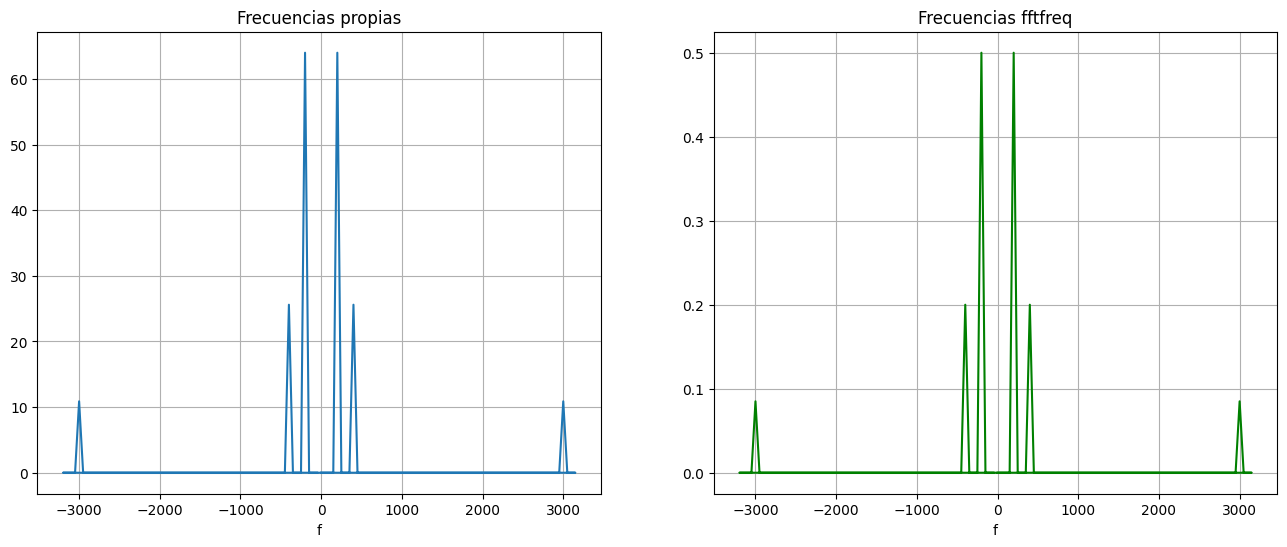

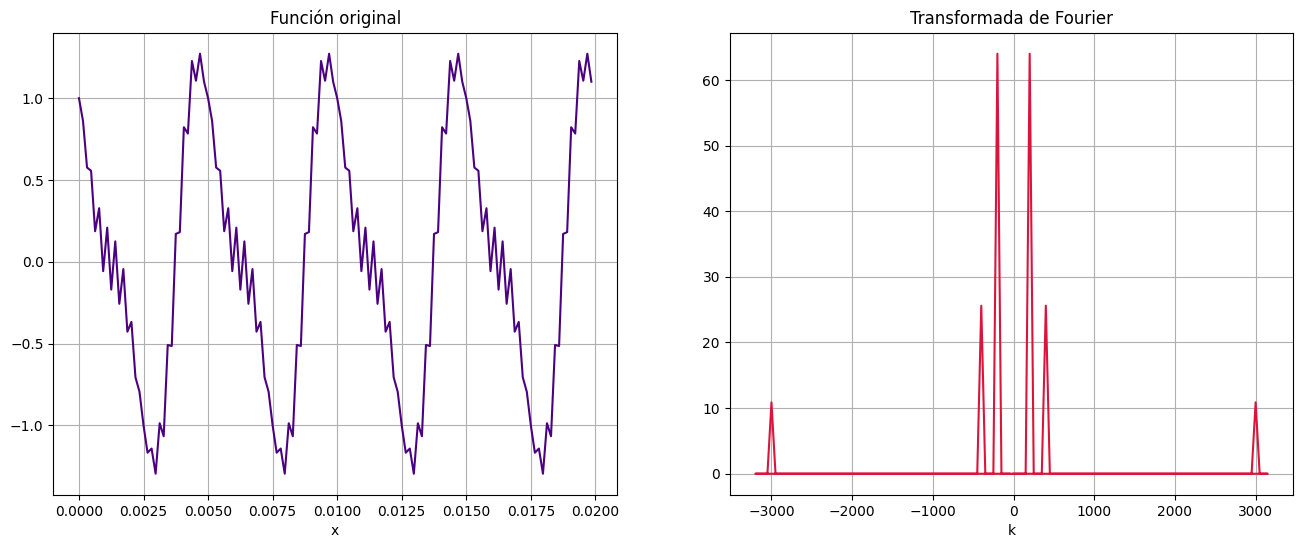

In [117]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# Construcción de la señal
N = 128 # number of point in the whole interval
f = 200.0 #  frequency in Hz
dt = 1 / (f * 32 ) #32 samples per unit frequency
t = np.linspace( 0, (N-1)*dt, N)
y = np.cos(2 * np.pi * f * t) - 0.4 * np.sin(2 * np.pi * (2*f) * t )+ 0.17*np.sin(2 * np.pi * (15*f) * t )

# 1) implemente de la transformada de fourier discreta
Fr = np.zeros(N, dtype="complex") #x_k
n = np.arange(N)

for k in range(N):
  Fr[k] = np.sum( y[:] * np.exp(- (0+1j) * 2 * np.pi * k * n[:] / N) )

Fr_R = np.real(Fr) # Tomo solo la parte real

# 2) Genere el arreglo de las frecuencias (ver documentación de fftfreq):
if N % 2 == 0: # Si N es par
  frecuencias = np.zeros(N)
  frecuencias_p1 = np.arange(N/2)          #parte 1, son positivos desde el cero hasta n/2 -1
  frecuencias_p2 = -np.arange(N/2)[::-1]-1 #parte 2, son negativos desde -n/2 hasta -1
  frecuencias[:int(N/2)] = frecuencias_p1 / (dt * N)
  frecuencias[int(N/2):] = frecuencias_p2 / (dt * N)

if N % 2 == 1: # Si N es impar
  frecuencias = np.zeros(N-1)
  frecuencias_p1 = np.arange((N-1)/2)          #parte 1, son positivos desde el cero hasta (n-1)/2
  frecuencias_p2 = -np.arange((N-1)/2)[::-1]-1 #parte 2, son negativos desde -(n-1)/2 hasta -1
  frecuencias[:int((N-1)/2)] = frecuencias_p1 / (dt * N)
  frecuencias[int((N-1)/2):] = frecuencias_p2 / (dt * N)
print("prueba\n",frecuencias)

# 3) Haga una gráfica comparando método propio con implementación de scipy.fftpack.fft
fft_x = fft(y) / N # FFT Normalized
freq = fftfreq(N, dt) # Recuperamos las frecuencias
print("fft scipy\n",freq)

fig1, (ax1,ax2) = plt.subplots(1,2, figsize=(16,6))

ax1.plot(frecuencias, np.abs(Fr))
ax1.grid(True)
ax1.set_xlabel("f")
ax1.set_title("Frecuencias propias")

ax2.plot(freq, np.abs(fft_x), color="green")
ax2.grid(True)
ax2.set_xlabel("f")
ax2.set_title("Frecuencias fftfreq")

plt.show()

# Gráfica prueba
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(16,6))

ax1.plot(t,y, color="indigo")
ax1.set_xlabel("x")
ax1.set_title("Función original")
ax1.grid(True)


ax2.plot(freq,np.abs(Fr), color="crimson")
ax2.set_xlabel("k")
ax2.set_title("Transformada de Fourier")
ax2.grid(True)

plt.show()

In [64]:
hola = np.arange(10) + 1
print(-hola[::-1])

[-10  -9  -8  -7  -6  -5  -4  -3  -2  -1]


EJERCICIO 2: FILTRO DE FOURIER

In [ ]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# 1) Almacene los datos de signal.dat. La columna 1 es el tiempo y la columna 2 es su señal f(t).
#Grafique su señal en función del tiempo.

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.

# 3) Haga un filtro pasa bajos que le permita filtrar el ruido de la señal del punto 1. #
#Use la gráfica de la transformada de fourier del punto 3 para determinar un valor apropiado de la frecuencia de corte que debe usar para filtrar dicho ruido de alta frecuencia.

# 4) Grafique la señal filtrada

EJERCICIO 3 (OPCIONAL: MUY DIVERTIDO SI OYEN LOS AUDIOS): FILTROS VIOLIN-TROMPETA

In [ ]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# 1) Almacene los datos de violin.wav (use wav.read('violin.wav')).
#Grafique su señal en función del tiempo y guarde dicha gráfica.

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.

# 3) Haga un filtro que elimine el pico principal. Grafique su señal filtrada.
#Escuche (OJO con el volumen!) sus datos filtrados.
#Repita lo anterior haciendo un filtro pasaaltos y uno pasabajos.

#NOTA: para el manejo de archivos .wav mire la documentacion de python de input-output en https://docs.scipy.org/doc/scipy-0.14.0/reference/io.html)

# 4) repita lo anterior para trumpet.wav que es la señal correspondiente al sonido
#de una trompeta tocando la misma nota que el violín del puntos anterior.

#Mire en la transformada de Fourier cuáles son las diferencias entre la señal del violin y de la trompeta.
# Qué hace que siendo la misma nota (misma frecuencia)el tiembre del violin de la trompeta sean tan diferentes...
